# 실습 4. Semantic Segmentation — 픽셀 단위 분류

**구성**
- **Part A. U-Net 직접 학습**: Oxford-IIIT Pet 데이터로 반려동물·배경·경계를 픽셀 단위로 분할
- **Part B. 사전학습 SegFormer로 가로 경관 분석**: 거리 사진을 도로·건물·식생·하늘 등으로 분할하고 녹시율(green view index) 계산

**목표**
- 분류(classification)와 분할(segmentation)의 출력 구조 차이 이해
- 인코더-디코더(encoder-decoder) 구조와 skip connection의 역할 확인
- 평가지표 IoU(Intersection over Union) 계산
- Transformer 기반 분할 모델(SegFormer)을 도시 경관 분석에 적용

**권장 런타임**: GPU (Part A 학습에 필요)

## 0. 환경 설정

In [1]:
# transformers: Hugging Face 사전학습 모델(SegFormer 등) 라이브러리
# koreanize-matplotlib: 그래프 한글 깨짐 방지   (-q: 설치 로그 생략)
!pip -q install transformers koreanize-matplotlib

In [2]:
import koreanize_matplotlib   # 그래프 한글 표시
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F                              # cross_entropy, interpolate 등
from torch.utils.data import Dataset, DataLoader, Subset     # 사용자 데이터셋 정의, 미니배치, 일부만 골라 쓰기
from torchvision import datasets                             # Oxford-IIIT Pet 데이터셋 내려받기
import torchvision.transforms.functional as TF               # 크기 조정·텐서 변환·정규화 함수
from torchvision.transforms import InterpolationMode         # 보간 방식(bilinear / nearest) 지정
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches                        # 범례용 색 상자
import time                                                  # epoch당 학습 시간 측정

torch.manual_seed(42); np.random.seed(42)               # 가중치 초기화·테스트 표본 선택을 매번 같게 (재현성)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ============================================================
# [실행 결과 해설]
# ============================================================
# - device: cuda → GPU(T4)를 사용 중. Part A의 U-Net 학습이 epoch당 약 25초로 끝나는 이유
#   (CPU였다면 수 분 이상 걸림)

device: cuda


---
# Part A. U-Net 직접 학습

## 1. 개념 정리

| 구분 | 이미지 분류 | Semantic segmentation |
|---|---|---|
| 출력 | 이미지당 클래스 1개 | **픽셀마다** 클래스 1개 |
| 출력 텐서 | `(B, n_classes)` | `(B, n_classes, H, W)` |
| 손실 함수 | Cross-entropy | 픽셀별 Cross-entropy의 평균 |

- **인코더(encoder)**: 합성곱·풀링으로 해상도를 줄이며 "무엇이 있는가"(의미 정보) 추출
- **디코더(decoder)**: 업샘플링으로 해상도를 복원하며 "어디에 있는가"(위치 정보) 복원
- **Skip connection**: 인코더의 고해상도 특징을 디코더에 직접 전달 → 경계선 정밀도 향상 (U-Net의 핵심)

## 2. 데이터: Oxford-IIIT Pet
- 37종 반려동물 이미지 약 7,400장, 픽셀 단위 마스크 제공
- 마스크 클래스: 반려동물(pet) / 배경(background) / 경계(border)
- 이미지는 양선형(bilinear), 마스크는 **최근접(nearest)** 보간으로 크기 조정 → 마스크에 존재하지 않는 중간 클래스 값 생성 방지

In [3]:
SIZE = 128                                           # 학습 이미지 크기 (128×128로 통일)
CLASSES = ["pet", "background", "border"]            # 마스크 클래스 0, 1, 2
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet 평균·표준편차 (RGB 정규화 표준값)

# ===== 데이터셋 클래스: (이미지, 마스크) 한 쌍을 꺼내 전처리 =====
class PetSeg(Dataset):
    def __init__(self, split):
        # target_types="segmentation": 이미지와 함께 픽셀 단위 마스크를 받음
        # "./data"는 Colab 기본 폴더(/content) 기준 → /content/data에 저장됨
        self.ds = datasets.OxfordIIITPet("./data", split=split,
                                         target_types="segmentation", download=True)
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        img, mask = self.ds[i]                                    # PIL 이미지 2장
        img  = TF.resize(img,  [SIZE, SIZE])                      # 이미지: 기본 bilinear 보간 (부드럽게)
        # 마스크: nearest 보간 → 1과 3 사이에 2.0 같은 "없는 클래스" 값이 생기지 않도록
        mask = TF.resize(mask, [SIZE, SIZE], interpolation=InterpolationMode.NEAREST)
        img  = TF.normalize(TF.to_tensor(img), MEAN, STD)        # 0~1 텐서 → 채널별 정규화
        mask = torch.as_tensor(np.array(mask), dtype=torch.long) - 1   # 1,2,3 → 0,1,2
        return img, mask                                          # (3, 128, 128), (128, 128)

train_ds = PetSeg("trainval")                       # 학습용 3,680장
test_full = PetSeg("test")                          # 테스트용 3,669장
test_ds = Subset(test_full, np.random.choice(len(test_full), 1000, replace=False))  # 평가 시간 단축
print("train:", len(train_ds), " test:", len(test_ds))

# num_workers=2: 이미지 읽기·크기 조정을 별도 프로세스 2개가 병렬로 처리 → GPU가 덜 기다림
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_ds, batch_size=64, num_workers=2)

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 처음 실행 시 이미지(792MB)와 마스크(19MB)를 내려받음 (약 30초). 이후엔 /content/data에 있는 파일 재사용
# - train 3,680장 / test 1,000장 (전체 테스트 3,669장 중 무작위 1,000장만 사용해 평가 시간 단축)

100%|██████████| 792M/792M [00:31<00:00, 25.1MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.15MB/s]


train: 3680  test: 1000


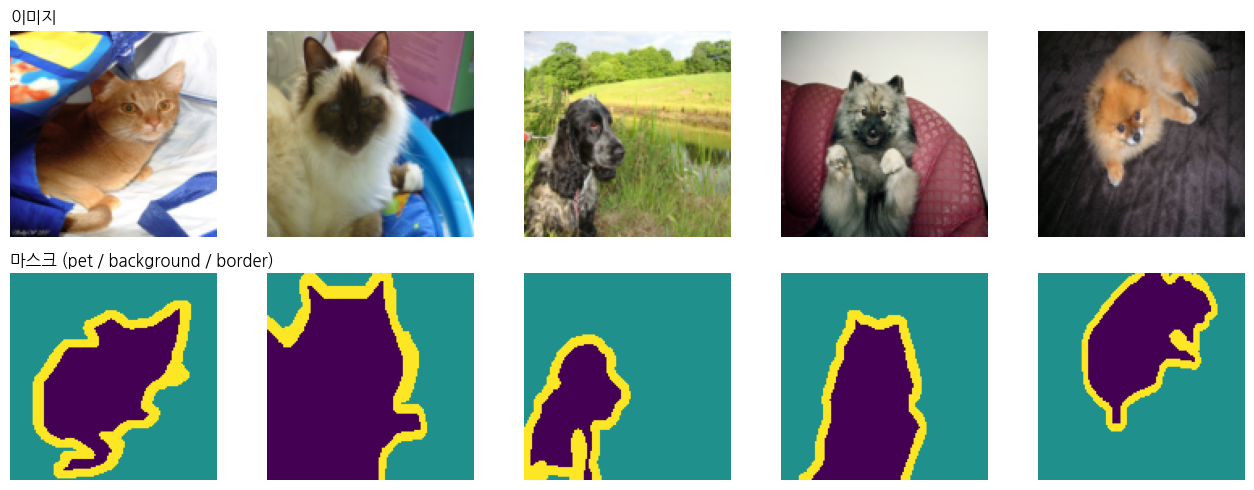

In [4]:
# 정규화를 되돌려(× std + mean) 사람이 볼 수 있는 0~1 색상으로 복원
def denorm(x):
    return (x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for k in range(5):
    img, mask = train_ds[k * 300]                                  # 300장 간격으로 5장
    axes[0, k].imshow(denorm(img).permute(1, 2, 0)); axes[0, k].axis("off")   # (C,H,W) → (H,W,C)로 바꿔야 imshow 가능
    axes[1, k].imshow(mask, cmap="viridis", vmin=0, vmax=2); axes[1, k].axis("off")   # 0=보라 pet, 1=청록 배경, 2=노랑 경계
axes[0, 0].set_title("이미지", loc="left"); axes[1, 0].set_title("마스크 (pet / background / border)", loc="left")
plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 마스크 색: 보라 = 반려동물(pet), 청록 = 배경(background), 노랑 = 경계(border)
# - border는 동물 윤곽을 따라 몇 픽셀 두께의 띠로 표시됨 → 털이 흩날리는 등 애매한 부분을 따로 분리한 클래스
# - 이미지마다 동물 크기·자세·배경이 제각각 → 단순한 색 구분이 아니라 "형태"를 학습해야 하는 문제

## 3. U-Net 구현
- 텐서 크기 변화: `128 → 64 → 32 → 16(bottleneck) → 32 → 64 → 128`
- `use_skip=False`로 두면 skip connection 자리에 0을 넣어, 구조는 같고 정보만 차단한 비교 모델이 됨

In [5]:
# ===== 기본 블록: (3×3 합성곱 → 배치정규화 → ReLU) × 2 =====
# padding=1이라 크기 유지, 채널 수만 c_in → c_out으로 바뀜
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self, n_classes=3, use_skip=True):
        super().__init__()
        self.use_skip = use_skip
        # 인코더: 채널은 늘리고(3→32→64→128) 해상도는 풀링으로 절반씩 줄임 → "무엇이 있는가"
        self.enc1, self.enc2, self.enc3 = conv_block(3, 32), conv_block(32, 64), conv_block(64, 128)
        self.bottleneck = conv_block(128, 256)                    # 가장 압축된 단계 (16×16)
        self.pool = nn.MaxPool2d(2)
        # 디코더: ConvTranspose2d(전치 합성곱)로 해상도를 2배씩 키움 → "어디에 있는가"
        # dec 입력 채널이 2배(256, 128, 64)인 이유: 업샘플링 결과 + skip 특징을 이어붙이기 때문
        self.up3, self.dec3 = nn.ConvTranspose2d(256, 128, 2, stride=2), conv_block(256, 128)
        self.up2, self.dec2 = nn.ConvTranspose2d(128, 64, 2, stride=2),  conv_block(128, 64)
        self.up1, self.dec1 = nn.ConvTranspose2d(64, 32, 2, stride=2),   conv_block(64, 32)
        self.head = nn.Conv2d(32, n_classes, 1)                   # 1×1 conv: 픽셀별 분류

    def _merge(self, up, skip):
        if not self.use_skip:
            skip = torch.zeros_like(skip)        # 비교 실험용: 모양은 같고 정보만 0으로 차단
        return torch.cat([up, skip], dim=1)                       # 채널 방향 결합

    def forward(self, x):
        e1 = self.enc1(x)                     # 32 × 128 × 128
        e2 = self.enc2(self.pool(e1))         # 64 × 64 × 64
        e3 = self.enc3(self.pool(e2))         # 128 × 32 × 32
        b  = self.bottleneck(self.pool(e3))   # 256 × 16 × 16
        d3 = self.dec3(self._merge(self.up3(b),  e3))   # 128 × 32 × 32   ← e3를 skip으로 받음
        d2 = self.dec2(self._merge(self.up2(d3), e2))   # 64 × 64 × 64    ← e2
        d1 = self.dec1(self._merge(self.up1(d2), e1))   # 32 × 128 × 128  ← e1
        return self.head(d1)                  # n_classes × 128 × 128

# 가짜 입력 2장으로 모양 확인
x = torch.randn(2, 3, SIZE, SIZE)
print("입력:", x.shape, "→ 출력:", UNet()(x).shape)
print("파라미터 수:", f"{sum(p.numel() for p in UNet().parameters()):,}")

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 입력 (2, 3, 128, 128) → 출력 (2, 3, 128, 128): 해상도는 그대로, 채널 3개 = 클래스별 점수
#   → 분류 모델처럼 "이미지당 1개"가 아니라 "픽셀마다" 3개 클래스 점수가 나옴 (segmentation의 핵심)
# - 파라미터 1,928,483개 (약 193만): 대부분 bottleneck(128→256)과 dec3(256→128)의 3×3 합성곱에 있음
#   use_skip=False여도 파라미터 수는 같음 → 비교 실험에서 "구조는 같고 정보 흐름만 다름"이 보장됨

입력: torch.Size([2, 3, 128, 128]) → 출력: torch.Size([2, 3, 128, 128])
파라미터 수: 1,928,483


## 4. 평가지표: IoU
$$\mathrm{IoU}_c = \frac{|\text{예측}_c \cap \text{정답}_c|}{|\text{예측}_c \cup \text{정답}_c|}, \qquad \mathrm{mIoU} = \frac{1}{C}\sum_c \mathrm{IoU}_c$$
- 픽셀 정확도(pixel accuracy)는 배경이 넓으면 과대평가되므로 IoU를 주로 사용

In [6]:
# ===== 평가: 혼동행렬로 픽셀 정확도와 클래스별 IoU 계산 =====
@torch.no_grad()
def evaluate(model, n_classes=3):
    model.eval()
    cm = torch.zeros(n_classes, n_classes, dtype=torch.long)   # 혼동행렬 (정답, 예측)
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(1).cpu()             # 픽셀마다 점수가 가장 큰 클래스
        # (정답, 예측) 쌍을 한 번에 세는 트릭: 정답×3 + 예측 → 0~8 번호 → bincount로 개수 → 3×3 표로
        cm += torch.bincount(n_classes * y.flatten() + pred.flatten(),
                             minlength=n_classes ** 2).view(n_classes, n_classes)
    tp = cm.diag().float()                                      # 대각선 = 맞힌 픽셀 수 (교집합)
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).float()            # 교집합 / (예측 + 정답 - 교집합) = 합집합
    return (tp.sum() / cm.sum()).item(), iou                    # (픽셀 정확도, 클래스별 IoU)

# ===== 학습: 매 epoch 끝에 테스트 성능 출력 =====
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); t0 = time.time()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)     # (B,C,H,W) vs (B,H,W): 픽셀별 CE
            opt.zero_grad(); loss.backward(); opt.step()
        acc, iou = evaluate(model)
        print(f"  epoch {ep+1}: pixel acc={acc:.3f}  mIoU={iou.mean():.3f}  "
              + "  ".join(f"{c}={v:.3f}" for c, v in zip(CLASSES, iou))
              + f"  ({time.time()-t0:.0f}s)")
    return model

# ============================================================
# [실행 결과 해설]
# ============================================================
# (출력 없음) 함수 정의만 하는 셀. 아래 학습·비교 실험에서 재사용

## 5. 학습
- GPU 기준 epoch당 약 30초~1분 (CPU에서는 매우 느리므로 GPU 런타임 권장)

In [7]:
# skip connection이 있는 기본 U-Net을 5 epoch 학습
unet = train_model(UNet(use_skip=True), epochs=5)

# ============================================================
# [실행 결과 해설]
# ============================================================
# epoch  pixel acc   mIoU    pet   background  border
#   1      0.694     0.397  0.305    0.699     0.187
#   2      0.832     0.618  0.685    0.815     0.356
#   3      0.825     0.609  0.680    0.809     0.338
#   4      0.851     0.651  0.721    0.836     0.396
#   5      0.860     0.651  0.741    0.849     0.362
#
# - 2 epoch 만에 mIoU 0.40 → 0.62로 급상승, 이후 0.65 근처에서 완만하게 오르내림
# - 클래스별 난이도: background(0.85) > pet(0.74) >> border(0.36)
#   · border는 가늘어서 1~2픽셀만 어긋나도 IoU가 크게 떨어짐 → 가장 어려운 클래스
# - pixel acc(0.86)가 mIoU(0.65)보다 훨씬 높음: 넓은 배경을 맞히는 것만으로 정확도가 올라가기 때문
#   → 4번 설명처럼 segmentation에서는 IoU로 평가해야 하는 이유
# - border IoU가 epoch 4(0.396) → 5(0.362)로 떨어진 것처럼 값이 출렁임 → 아직 수렴 전, epoch를 늘리면 개선 여지 있음

  epoch 1: pixel acc=0.694  mIoU=0.397  pet=0.305  background=0.699  border=0.187  (26s)
  epoch 2: pixel acc=0.832  mIoU=0.618  pet=0.685  background=0.815  border=0.356  (23s)
  epoch 3: pixel acc=0.825  mIoU=0.609  pet=0.680  background=0.809  border=0.338  (24s)
  epoch 4: pixel acc=0.851  mIoU=0.651  pet=0.721  background=0.836  border=0.396  (24s)
  epoch 5: pixel acc=0.860  mIoU=0.651  pet=0.741  background=0.849  border=0.362  (25s)


## 6. 예측 결과 시각화

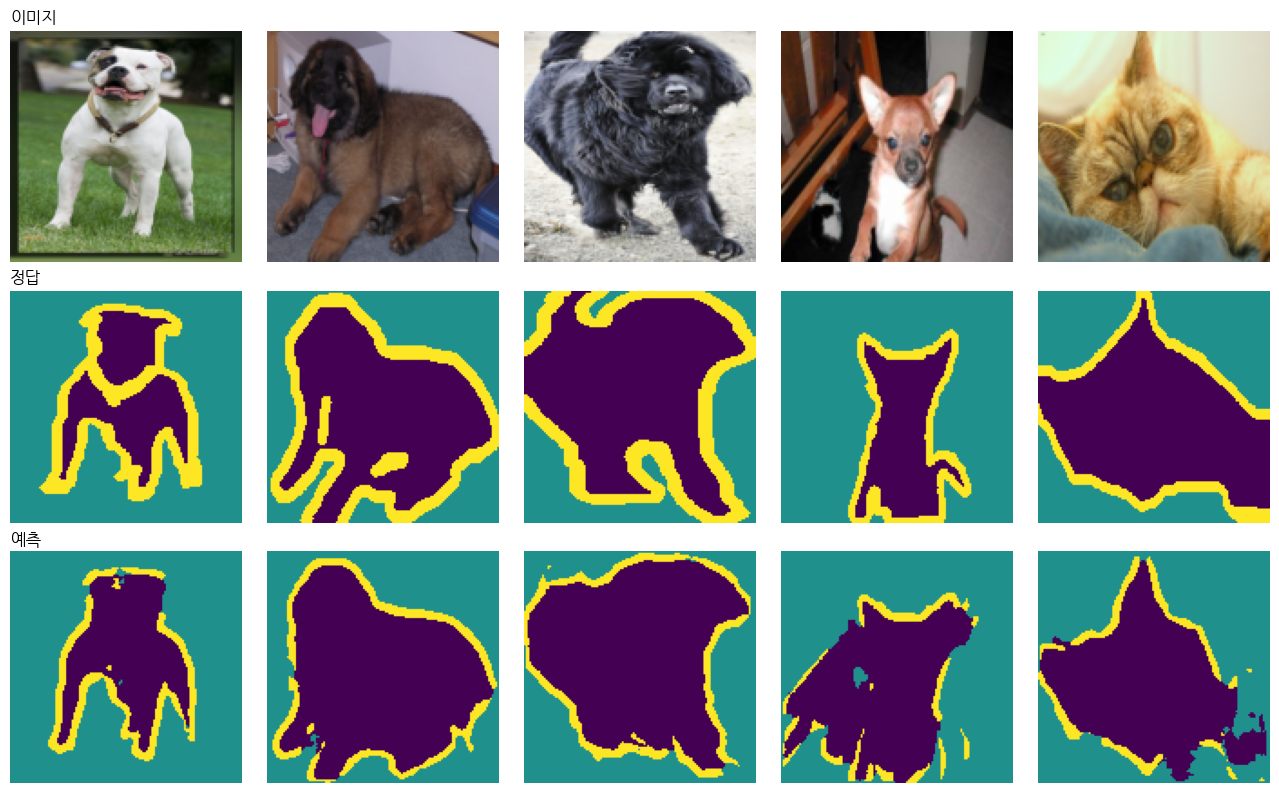

In [8]:
# ===== 테스트 이미지 5장의 정답과 예측 비교 =====
@torch.no_grad()
def show_predictions(model, n=5):
    model.eval()
    fig, axes = plt.subplots(3, n, figsize=(13, 8))       # 행: 이미지 / 정답 / 예측
    for k in range(n):
        img, mask = test_ds[k * 50]
        pred = model(img.unsqueeze(0).to(device)).argmax(1)[0].cpu()   # 배치 차원 추가 → 예측 → 다시 제거
        axes[0, k].imshow(denorm(img).permute(1, 2, 0))
        axes[1, k].imshow(mask, cmap="viridis", vmin=0, vmax=2)
        axes[2, k].imshow(pred, cmap="viridis", vmin=0, vmax=2)
        for r in range(3): axes[r, k].axis("off")
    for r, t in enumerate(["이미지", "정답", "예측"]):
        axes[r, 0].set_title(t, loc="left")
    plt.tight_layout(); plt.show()

show_predictions(unet)

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 전체 윤곽은 대체로 정확: 1~3번째 강아지는 몸통·다리 형태와 경계 띠(노랑)를 잘 따라감
# - 실패 사례:
#   · 4번째(치와와): 귀·다리 같은 가는 부분을 놓치고, 바닥·의자 쪽 배경 일부를 pet(보라)으로 잘못 칠함
#     → 배경이 복잡하고 동물과 색이 비슷하면 혼동
#   · 5번째(고양이): 오른쪽 아래 담요까지 pet으로 번짐 → 털색과 비슷한 질감을 동물로 착각
# - 예측된 경계 띠는 정답보다 가늘거나 끊기는 곳이 있음 → border IoU가 낮은(0.36) 이유가 눈으로 확인됨

## 7. 비교 실험: skip connection 제거
- 동일 구조에서 skip connection의 정보만 차단
- 관찰 포인트: 전체 mIoU보다 **border 클래스 IoU**(경계선 정밀도)의 차이

  epoch 1: pixel acc=0.758  mIoU=0.438  pet=0.589  background=0.724  border=0.000  (25s)
  epoch 2: pixel acc=0.828  mIoU=0.584  pet=0.690  background=0.814  border=0.248  (25s)
  epoch 3: pixel acc=0.817  mIoU=0.591  pet=0.641  background=0.812  border=0.319  (25s)
  epoch 4: pixel acc=0.832  mIoU=0.578  pet=0.698  background=0.821  border=0.216  (26s)
  epoch 5: pixel acc=0.853  mIoU=0.640  pet=0.723  background=0.846  border=0.353  (26s)


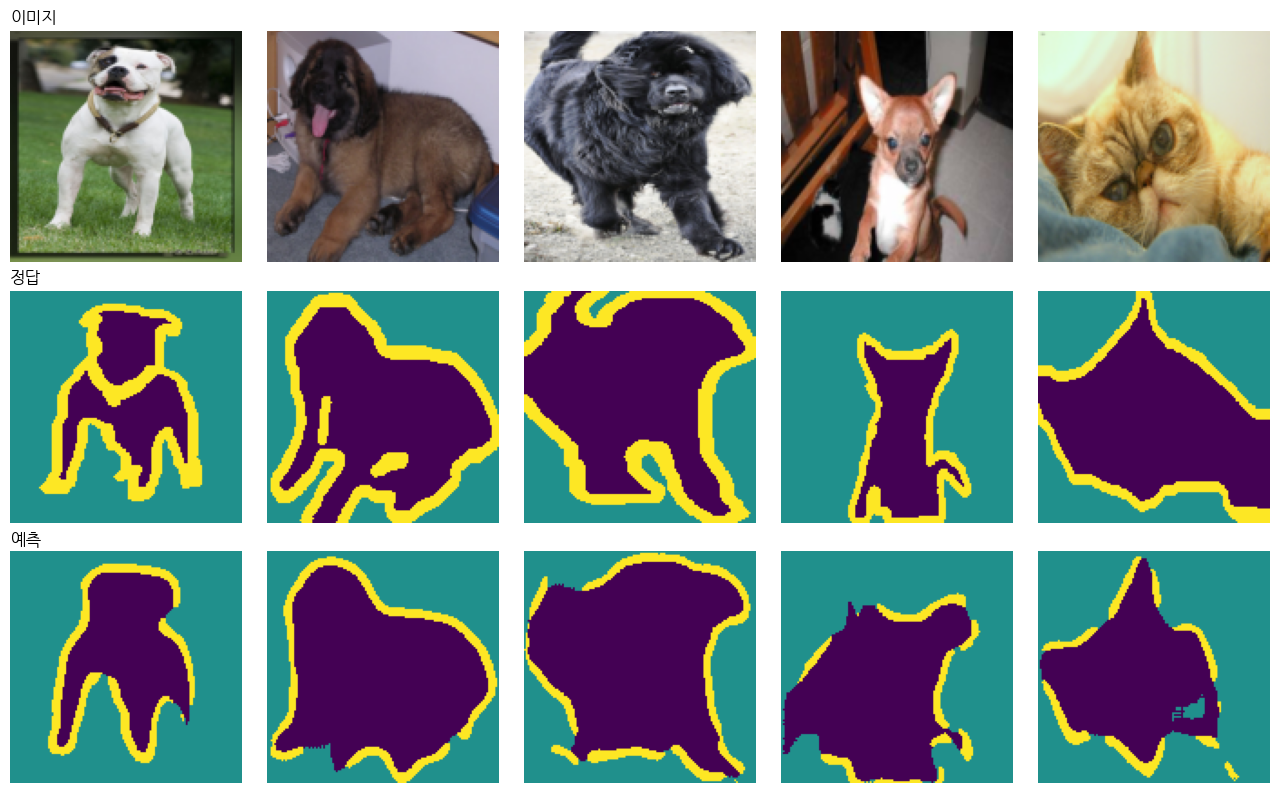

In [9]:
# skip connection의 정보를 0으로 차단한 U-Net (구조·파라미터 수는 동일)
unet_noskip = train_model(UNet(use_skip=False), epochs=5)
show_predictions(unet_noskip)

# ============================================================
# [실행 결과 해설]
# ============================================================
# epoch  pixel acc   mIoU    pet   background  border
#   1      0.758     0.438  0.589    0.724     0.000   ← 첫 epoch엔 경계를 전혀 못 찾음
#   2      0.828     0.584  0.690    0.814     0.248
#   3      0.817     0.591  0.641    0.812     0.319
#   4      0.832     0.578  0.698    0.821     0.216
#   5      0.853     0.640  0.723    0.846     0.353
#
# - skip 있는 모델(최종 mIoU 0.651, border 0.362)과 비교하면 최종값 차이는 작지만,
#   학습 과정의 border IoU가 0.000 → 0.248 → 0.319 → 0.216으로 낮고 불안정함
#   → 세밀한 위치 정보 없이 16×16 요약만으로 경계를 복원하기 어렵다는 뜻
# - 예측 그림: 윤곽이 둥글고 매끈하게 뭉개짐 (1번째 강아지 다리 사이 간격·귀 모양이 사라짐)
#   · 반대로 skip 모델에서 생긴 배경 오분류(4·5번째)는 오히려 적음 → 큰 형태 위주로만 판단하기 때문
# - 자세한 수치 비교는 추가 과제 1 참고

---
# Part B. 사전학습 SegFormer로 가로 경관 분석

- **SegFormer**: Transformer 인코더(계층형 self-attention) + 경량 MLP 디코더로 구성된 분할 모델
  → 실습 3의 Attention이 분할 문제에 적용된 사례
- Cityscapes(유럽 도시 거리 영상, 19개 클래스)로 사전학습된 모델 사용
- 활용 예: 거리 사진에서 **녹시율(green view index)**, 하늘 개방도(sky view), 도로·보도 비율 산출

In [10]:
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
from PIL import Image

# SegFormer-b0 (가장 작은 버전), Cityscapes 19개 클래스로 미세조정, 1024×1024 입력 기준
name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)      # 크기 조정·정규화 등 입력 전처리 담당
segformer = SegformerForSemanticSegmentation.from_pretrained(name).to(device).eval()   # 평가 모드
id2label = segformer.config.id2label                            # 클래스 번호 → 이름
print(list(id2label.values()))

# ============================================================
# [실행 결과 해설]
# ============================================================
# - "HF_TOKEN" 경고는 무시해도 됨: 로그인 없이 내려받아 속도 제한이 걸릴 수 있다는 안내일 뿐
# - 모델 크기 15MB(b0)로 매우 가벼움
# - 19개 클래스: 도로·보도·건물·벽·울타리·기둥·신호등·표지판·식생·지형·하늘·사람·라이더·승용차·트럭·버스·기차·오토바이·자전거
#   → "간판", "전선", "볼라드"처럼 한국 거리에 흔한 요소는 클래스에 없음 (추가 과제 5 참고)

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

['road', 'sidewalk', 'building', 'wall', 'fence', 'pole', 'traffic light', 'traffic sign', 'vegetation', 'terrain', 'sky', 'person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']


## 8. 거리 사진 불러오기
- Colab: 아래 셀 실행 시 파일 선택 창에서 거리 사진 업로드
- 로컬 실행: `IMAGE_PATH`에 파일 경로 직접 지정
- 사람 눈높이에서 정면을 찍은 가로 사진이 적합 (Cityscapes 촬영 조건과 유사)

In [20]:
# Google Drive 연결 → Drive에 있는 거리 사진을 읽기 위해 필요
from google.colab import drive
drive.mount('/content/drive')

import os
# 노트북이 있는 폴더. 사진은 이 폴더 기준 상대경로(image/...)로 지정
# 주의: os.chdir로 작업 폴더를 옮기면 Part A의 "./data"(Pet 데이터) 경로가 깨지므로 이동하지 않음
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/5_스마트도시데이터분석_colab/lecture10_advanced_models"
os.chdir("/content")                                   # 혹시 다른 폴더로 옮겨져 있으면 Colab 기본 폴더로 복귀
rel = lambda p: os.path.join(BASE_DIR, p)              # 상대경로 → 전체 경로
print("image 폴더:", sorted(os.listdir(rel("image"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
image 폴더: ['builtup_workflow.png', '스크린샷 2026-11-08 065739.png', '스크린샷 2026-11-08 065827.png']


이미지 크기: (2712, 1737)


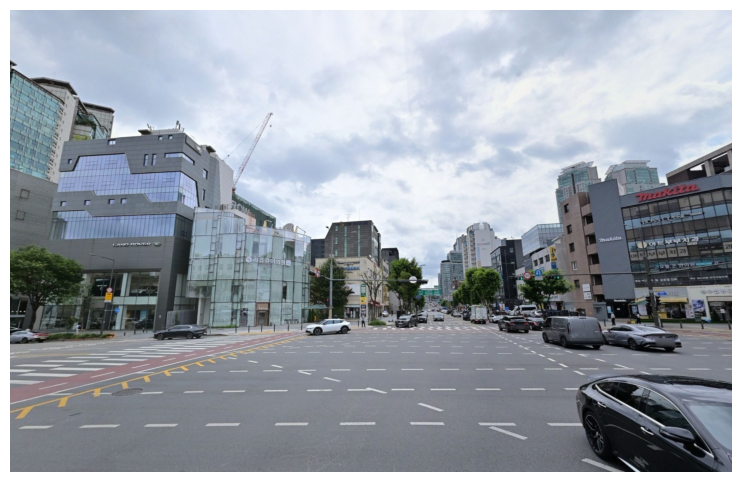

In [21]:
# 분석할 거리 사진 경로 (BASE_DIR 기준 상대경로)
# None으로 두면 아래에서 파일 업로드 창이 뜸
IMAGE_PATH = "image/스크린샷 2026-11-08 065739.png"

if IMAGE_PATH is None:                       # 경로를 지정하지 않은 경우에만 업로드
    from google.colab import files
    uploaded = files.upload()
    IMAGE_PATH = list(uploaded.keys())[0]

image = Image.open(rel(IMAGE_PATH)).convert("RGB")   # PNG의 투명 채널 등을 제거하고 RGB 3채널로 통일
print("이미지 크기:", image.size)
plt.figure(figsize=(10, 6)); plt.imshow(image); plt.axis("off"); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 이미지 크기 2712×1737 (가로×세로): 사람 눈높이에서 도로 정면을 찍은 사진 → Cityscapes 촬영 조건과 비슷해 적합
# - 넓은 교차로, 양쪽 상업 건물, 멀리 작은 가로수가 보이는 거리 (분할 결과는 9번)

## 9. 분할 수행
- 모델 출력은 입력의 1/4 해상도 → 원본 크기로 업샘플링 후 픽셀별 argmax

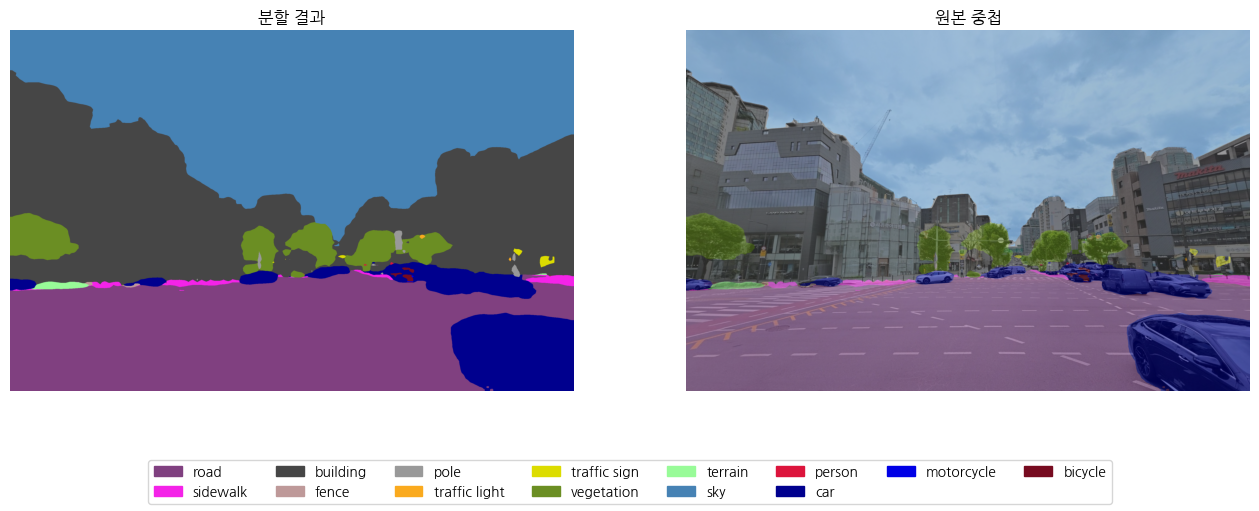

In [16]:
# Cityscapes 표준 색상표 (클래스 번호 순서대로 RGB)
PALETTE = np.array([
    [128, 64,128], [244, 35,232], [ 70, 70, 70], [102,102,156], [190,153,153],
    [153,153,153], [250,170, 30], [220,220,  0], [107,142, 35], [152,251,152],
    [ 70,130,180], [220, 20, 60], [255,  0,  0], [  0,  0,142], [  0,  0, 70],
    [  0, 60,100], [  0, 80,100], [  0,  0,230], [119, 11, 32]], dtype=np.uint8)

with torch.no_grad():
    inputs = processor(images=image, return_tensors="pt").to(device)   # 전처리된 텐서
    logits = segformer(**inputs).logits                         # (1, 19, H/4, W/4)
    # 1/4 해상도 점수를 원본 크기로 부드럽게 확대 (image.size는 (W, H)라 뒤집어서 (H, W))
    logits = F.interpolate(logits, size=image.size[::-1],       # (H, W)
                           mode="bilinear", align_corners=False)
    seg = logits.argmax(1)[0].cpu().numpy()                     # 픽셀마다 가장 점수 높은 클래스 → (H, W)

color = PALETTE[seg]                                            # 클래스 번호 → 색 (H, W, 3)
overlay = (0.5 * np.array(image) + 0.5 * color).astype(np.uint8)   # 원본과 반반 섞어 겹쳐 보기

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(color); axes[0].set_title("분할 결과")
axes[1].imshow(overlay); axes[1].set_title("원본 중첩")
for ax in axes: ax.axis("off")
present = np.unique(seg)                                        # 사진에 실제로 나온 클래스만 범례에 표시
handles = [mpatches.Patch(color=PALETTE[i] / 255, label=id2label[int(i)]) for i in present]
fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 8))
plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 큰 영역은 정확: 하늘(파랑)·건물(진회색)·도로(보라)·차량(남색)의 경계가 원본과 잘 맞음
#   · 오른쪽 아래 가까운 검은 승용차, 멀리 늘어선 차량들도 car로 정확히 분리
# - 가로수(연두)는 멀리 있는 작은 나무까지 잡아냄. 왼쪽 아래 화단은 terrain(연녹색)으로 분류
# - 작은 오류: 오른쪽 건물의 간판·현수막 일부를 traffic sign(노랑)으로 분류 → Cityscapes에 "간판" 클래스가 없기 때문
# - 건물 유리 외벽의 하늘 반사, 크레인도 대체로 building/sky로 무난하게 처리됨

## 10. 가로 경관 지표 산출
- **녹시율(green view index)**: 시야 내 식생(vegetation) 픽셀 비율
- **하늘 비율(sky view)**: 하늘(sky) 픽셀 비율 → 개방감·위요감 지표
- 클래스별 픽셀 비율 전체를 막대그래프로 제시

녹시율 (vegetation): 3.6%
하늘 비율 (sky):      36.6%
건물 비율 (building): 27.6%
도로 비율 (road):     25.0%


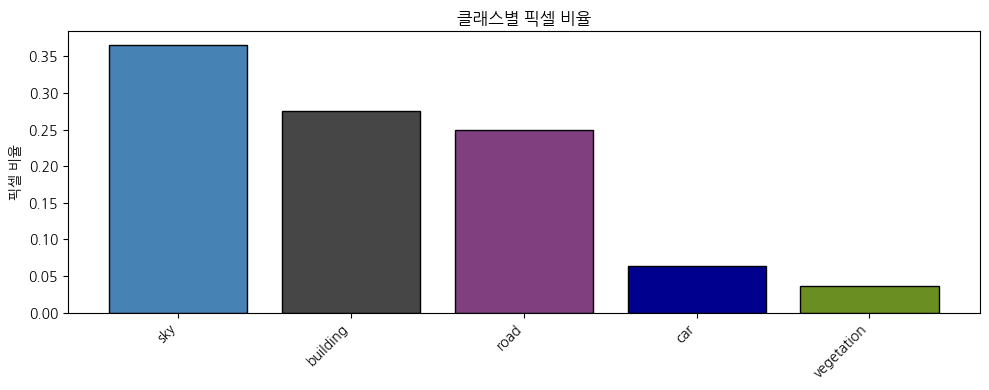

In [17]:
# 클래스별 픽셀 개수 → 전체 대비 비율
counts = np.bincount(seg.flatten(), minlength=len(id2label))   # 19개 클래스 각각의 픽셀 수
ratio = counts / counts.sum()
label2id = {v: int(k) for k, v in id2label.items()}            # 이름 → 번호 (예: 'vegetation' → 8)

print(f"녹시율 (vegetation): {ratio[label2id['vegetation']]:.1%}")
print(f"하늘 비율 (sky):      {ratio[label2id['sky']]:.1%}")
print(f"건물 비율 (building): {ratio[label2id['building']]:.1%}")
print(f"도로 비율 (road):     {ratio[label2id['road']]:.1%}")

order = np.argsort(ratio)[::-1]                                 # 비율 큰 순서
order = order[ratio[order] > 0.005]                             # 0.5% 이상만 표시
plt.figure(figsize=(10, 4))
plt.bar([id2label[int(i)] for i in order], ratio[order], color=PALETTE[order] / 255, edgecolor="k")
plt.ylabel("픽셀 비율"); plt.xticks(rotation=45, ha="right"); plt.title("클래스별 픽셀 비율")
plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# 하늘 36.6% > 건물 27.6% > 도로 25.0% > 차량 6.3% > 식생 3.6%
# - 녹시율 3.6%: 가로수가 작고 멀리 있어 시야 속 녹지가 매우 적은 거리
# - 하늘 36.6%: 넓은 교차로 + 도로 폭이 넓어 시야가 트임 → 개방감은 높지만 그늘·녹음은 부족
# - 상위 5개 클래스가 약 99%를 차지 → 보도·기둥·표지판 등은 0.5% 미만으로 그래프에서 제외됨
# - 같은 방식으로 다른 거리 사진과 비교한 결과는 추가 과제 3 참고 (가로수 대로: 녹시율 41.0%)

## 11. 추가 과제
1. Part A에서 skip connection 유무에 따라 border IoU가 얼마나 달라지는가? 그 이유는?
2. 입력 크기 `SIZE`를 64, 256으로 바꾸면 성능·학습 시간은 어떻게 변하는가?
3. 다른 거리의 사진을 비교해 녹시율 차이를 산출하라.
4. 모델을 `nvidia/segformer-b2-finetuned-cityscapes-1024-1024`로 바꾸면 결과가 얼마나 달라지는가?
5. (토론) 유럽 도시(Cityscapes)로 학습한 모델을 한국 거리 사진에 적용할 때 생길 수 있는 오류는? 간판·전신주·좁은 이면도로 등에서 확인해 보라.

### 추가 과제 1. skip connection 유무에 따른 border IoU 비교
- 5 epoch 학습이 끝난 두 모델(`unet`, `unet_noskip`)을 같은 테스트 1,000장으로 다시 평가
- border(경계) 클래스만 따로 시각화해 경계선이 얼마나 정확한지 비교

모델             pixel acc    mIoU         pet  background      border
U-Net (skip)       0.860   0.651       0.741       0.849       0.362
U-Net (no skip)     0.853   0.640       0.723       0.846       0.353
차이(skip-no)        0.007   0.010       0.018       0.003       0.010


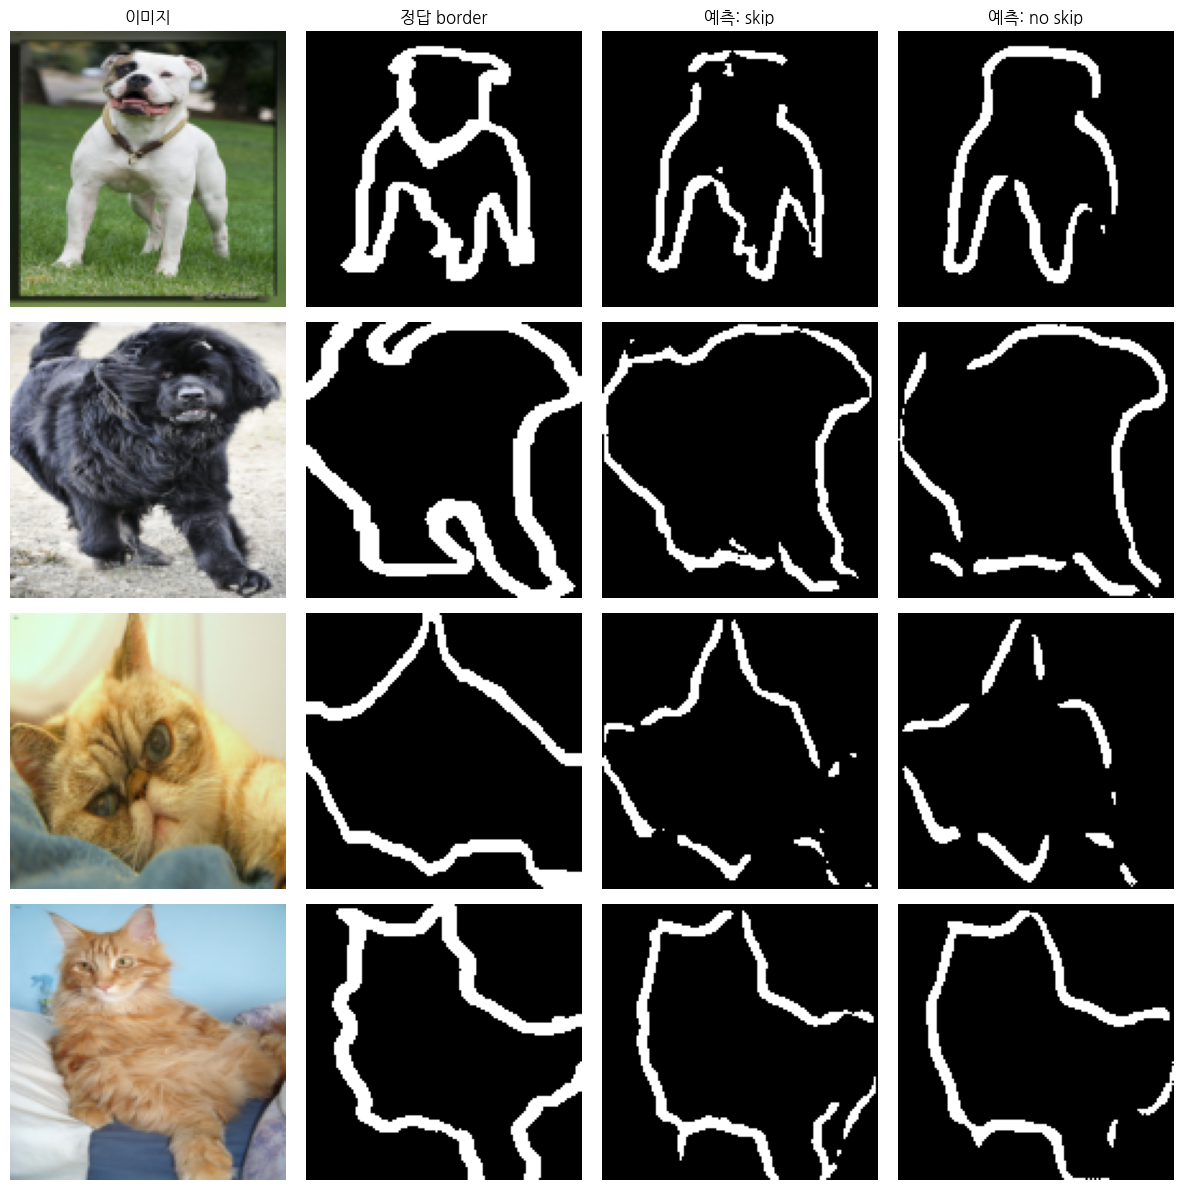

In [22]:
# ===== 두 모델 최종 성능 비교 =====
acc_s, iou_s = evaluate(unet)           # skip connection 있음
acc_n, iou_n = evaluate(unet_noskip)    # skip connection 없음 (0으로 차단)

print(f"{'모델':<14}{'pixel acc':>10}{'mIoU':>8}" + "".join(f"{c:>12}" for c in CLASSES))
for name, acc, iou in [("U-Net (skip)", acc_s, iou_s), ("U-Net (no skip)", acc_n, iou_n)]:
    print(f"{name:<14}{acc:>10.3f}{iou.mean():>8.3f}" + "".join(f"{v:>12.3f}" for v in iou))
print(f"{'차이(skip-no)':<14}{acc_s-acc_n:>10.3f}{(iou_s-iou_n).mean():>8.3f}" + "".join(f"{v:>12.3f}" for v in iou_s - iou_n))

# ===== border 클래스만 시각화 =====
# 흰색 = border(경계)로 분류된 픽셀. 정답과 비교해 경계선이 얼마나 가늘고 정확한지 확인
@torch.no_grad()
def show_border(models, idx=(0, 100, 200, 300)):
    fig, axes = plt.subplots(len(idx), 2 + len(models), figsize=(3 * (2 + len(models)), 3 * len(idx)))
    for r, k in enumerate(idx):
        img, mask = test_ds[k]
        axes[r, 0].imshow(denorm(img).permute(1, 2, 0))
        axes[r, 1].imshow(mask == 2, cmap="gray")                       # 정답 border (클래스 2)
        for c, (name, m) in enumerate(models.items()):
            m.eval()
            pred = m(img.unsqueeze(0).to(device)).argmax(1)[0].cpu()
            axes[r, 2 + c].imshow(pred == 2, cmap="gray")               # 예측 border
        for ax in axes[r]: ax.axis("off")
    for c, t in enumerate(["이미지", "정답 border"] + [f"예측: {n}" for n in models]):
        axes[0, c].set_title(t)
    plt.tight_layout(); plt.show()

show_border({"skip": unet, "no skip": unet_noskip})

# ============================================================
# [실행 결과 해설]
# ============================================================
# 모델             pixel acc   mIoU    pet    background   border
# skip               0.860     0.651   0.741     0.849      0.362
# no skip            0.853     0.640   0.723     0.846      0.353
#
# Q. border IoU가 얼마나 달라지나?  → 0.362 vs 0.353, 약 0.01 차이로 "생각보다 작음"
# - 숫자 차이는 작지만 그림에서는 차이가 분명함
#   · skip: 강아지 다리 사이, 귀, 꼬리처럼 가늘고 복잡한 경계를 따라감
#   · no skip: 윤곽이 둥글게 뭉개지고(다리 두 개가 하나로 합쳐짐), 경계선이 중간중간 끊김
# - 이유: 인코더가 128 → 16으로 줄이는 동안 세밀한 위치 정보가 사라지는데,
#   skip connection은 128·64·32 해상도의 특징을 디코더에 바로 넘겨 "정확히 어디가 경계인지"를 복원해 줌.
#   skip이 없으면 디코더는 16×16 요약 정보만으로 업샘플링해야 해서 경계가 흐릿해짐
# - 차이가 작게 나온 이유(추정):
#   · 5 epoch만 학습해 두 모델 모두 아직 덜 수렴함 (학습 중 border IoU가 0.33~0.40 사이에서 오르내림)
#   · Pet 데이터의 border는 두께가 몇 픽셀인 굵은 띠라 대략적인 위치만 맞혀도 IoU가 어느 정도 나옴
#   · 한 번의 실행 결과라 무작위 초기화에 따른 편차(±0.02 정도)와 비슷한 크기
#   → epoch를 늘리거나 여러 시드로 반복하면 차이가 더 뚜렷해질 가능성이 큼

### 추가 과제 2. 입력 크기 `SIZE`를 64, 256으로 바꾸기
- 이미지·마스크를 해당 크기로 다시 만들고, 같은 조건(5 epoch, lr=1e-3, skip 있음)으로 새로 학습
- 테스트 이미지는 128 실험과 **같은 1,000장**을 사용 (`test_ds.indices` 재사용)
- 주의: IoU는 각 크기로 줄인 마스크 기준으로 계산되므로, 해상도가 낮을수록 경계(border)가 두껍게 뭉개져 평가 자체가 달라짐

===== SIZE = 64 =====
  epoch 1: pixel acc=0.771  mIoU=0.499  pet=0.549  background=0.748  border=0.201  (18s)
  epoch 2: pixel acc=0.826  mIoU=0.608  pet=0.665  background=0.811  border=0.347  (19s)
  epoch 3: pixel acc=0.847  mIoU=0.640  pet=0.710  background=0.837  border=0.375  (20s)
  epoch 4: pixel acc=0.854  mIoU=0.648  pet=0.723  background=0.844  border=0.376  (18s)
  epoch 5: pixel acc=0.850  mIoU=0.633  pet=0.719  background=0.844  border=0.337  (18s)
===== SIZE = 256 =====
  epoch 1: pixel acc=0.733  mIoU=0.457  pet=0.539  background=0.703  border=0.127  (83s)
  epoch 2: pixel acc=0.786  mIoU=0.527  pet=0.606  background=0.764  border=0.211  (89s)
  epoch 3: pixel acc=0.799  mIoU=0.560  pet=0.614  background=0.776  border=0.292  (89s)
  epoch 4: pixel acc=0.814  mIoU=0.574  pet=0.648  background=0.784  border=0.290  (89s)
  epoch 5: pixel acc=0.819  mIoU=0.590  pet=0.641  background=0.789  border=0.339  (89s)

  SIZE  pixel acc    mIoU         pet  background      border   

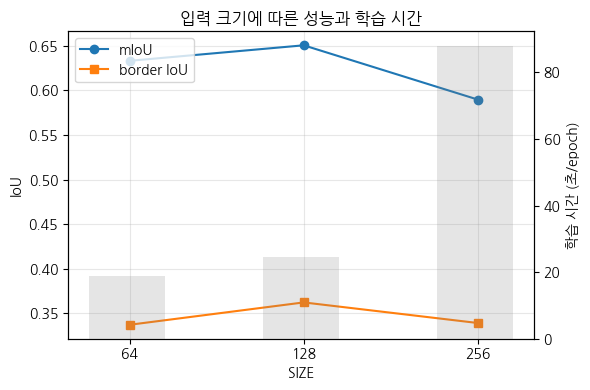

In [25]:
# ===== SIZE별 데이터를 새로 만들고 학습하는 함수 =====
test_idx = test_ds.indices                      # 128 실험과 같은 테스트 1,000장

def run_size(s, epochs=5):
    # PetSeg, train_model, evaluate가 전역 변수 SIZE·train_loader·test_loader를 쓰므로 global로 교체
    global SIZE, train_loader, test_loader
    SIZE = s
    tr = PetSeg("trainval")
    te = Subset(PetSeg("test"), test_idx)
    train_loader = DataLoader(tr, batch_size=32, shuffle=True, num_workers=2)
    test_loader  = DataLoader(te, batch_size=64, num_workers=2)
    torch.manual_seed(42)                       # 같은 초기 가중치로 공정하게 비교
    print(f"===== SIZE = {s} =====")
    t0 = time.time()
    model = train_model(UNet(use_skip=True), epochs=epochs)
    sec = (time.time() - t0) / epochs
    acc, iou = evaluate(model)
    return {"acc": acc, "iou": iou, "sec": sec}

size_res = {s: run_size(s) for s in [64, 256]}

# 128은 이미 학습한 unet 결과를 그대로 사용 (시간은 위 학습 로그의 epoch당 평균 약 24초)
SIZE = 128
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)   # 원래 설정으로 복구
test_loader  = DataLoader(test_ds, batch_size=64, num_workers=2)
acc128, iou128 = evaluate(unet)
size_res[128] = {"acc": acc128, "iou": iou128, "sec": 24.4}

# ===== 결과 표 =====
print(f"\n{'SIZE':>6}{'pixel acc':>11}{'mIoU':>8}" + "".join(f"{c:>12}" for c in CLASSES) + f"{'초/epoch':>10}")
for s in sorted(size_res):
    r = size_res[s]
    print(f"{s:>6}{r['acc']:>11.3f}{r['iou'].mean():>8.3f}" + "".join(f"{v:>12.3f}" for v in r["iou"]) + f"{r['sec']:>10.1f}")

# ===== 그래프: 크기별 mIoU·border IoU와 학습 시간 =====
ss = sorted(size_res)
fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(ss, [size_res[s]["iou"].mean() for s in ss], "o-", label="mIoU")
ax1.plot(ss, [size_res[s]["iou"][2] for s in ss], "s-", label="border IoU")
ax1.set_xscale("log", base=2); ax1.set_xticks(ss, ss); ax1.set_xlabel("SIZE"); ax1.set_ylabel("IoU")
ax2 = ax1.twinx()
ax2.bar(ss, [size_res[s]["sec"] for s in ss], width=[s * 0.3 for s in ss], alpha=0.2, color="gray", label="초/epoch")
ax2.set_ylabel("학습 시간 (초/epoch)")
ax1.legend(loc="upper left"); ax1.grid(alpha=.3); plt.title("입력 크기에 따른 성능과 학습 시간")
plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# SIZE  pixel acc   mIoU    pet   background  border   초/epoch
#   64     0.850    0.633  0.719    0.844     0.337      18.8
#  128     0.860    0.651  0.741    0.849     0.362      24.4
#  256     0.819    0.590  0.641    0.789     0.339      87.9   (모두 5 epoch, T4 GPU)
#
# [학습 시간] 픽셀 수가 4배씩 늘어나므로 계산량도 약 4배
# - 64 → 128은 1.3배밖에 안 늘었음: 작은 크기에서는 GPU 계산보다 이미지 불러오기·크기 조정(CPU)이 병목
# - 128 → 256은 3.6배: 이제 GPU 계산이 병목이 되어 픽셀 수에 거의 비례해 느려짐
#
# [성능] 128이 가장 좋고, 256이 오히려 가장 나쁨 (mIoU 0.590)
# - 256은 학습 부족: mIoU가 0.457 → 0.527 → 0.560 → 0.574 → 0.590으로 매 epoch 꾸준히 오르는 중
#   같은 5 epoch라도 큰 이미지는 배워야 할 세부가 많아 더 오래 학습해야 함
# - 수용 영역(receptive field) 문제: U-Net은 풀링을 3번만 하므로 한 픽셀이 "보는" 범위가 픽셀 단위로 고정됨
#   256에서는 같은 범위가 동물 몸의 더 작은 부분에 해당 → 전체 형태를 파악하기 어려워 pet/background 혼동 증가
#   (깊이를 늘리거나 풀링을 한 번 더 넣으면 개선 가능)
# - 64는 128과 큰 차이가 없음(mIoU -0.018): 반려동물처럼 큰 물체는 저해상도에서도 모양이 충분히 보임.
#   단, 평가 마스크도 64로 줄여서 계산하므로 border가 굵게 뭉개져 "맞히기 쉬운" 상태라는 점에 주의
#   → 크기별 IoU를 엄밀히 비교하려면 예측을 원본 해상도로 키워 같은 정답 마스크로 평가해야 함
#
# [결론] 해상도를 높인다고 바로 좋아지지 않음. 해상도를 올리면 학습 시간(epoch 수)과 네트워크 깊이도 함께 늘려야 함.
#        시간 대비 효율은 이 데이터에서는 128이 가장 균형적

### 추가 과제 3. 두 거리 사진의 녹시율 비교
- 사진 A: `image/스크린샷 2026-11-08 065739.png` (8번에서 분석한 사진)
- 사진 B: `image/스크린샷 2026-11-08 065827.png`
- 두 사진을 같은 SegFormer-b0로 분할해 녹시율·하늘·건물·도로 비율을 비교

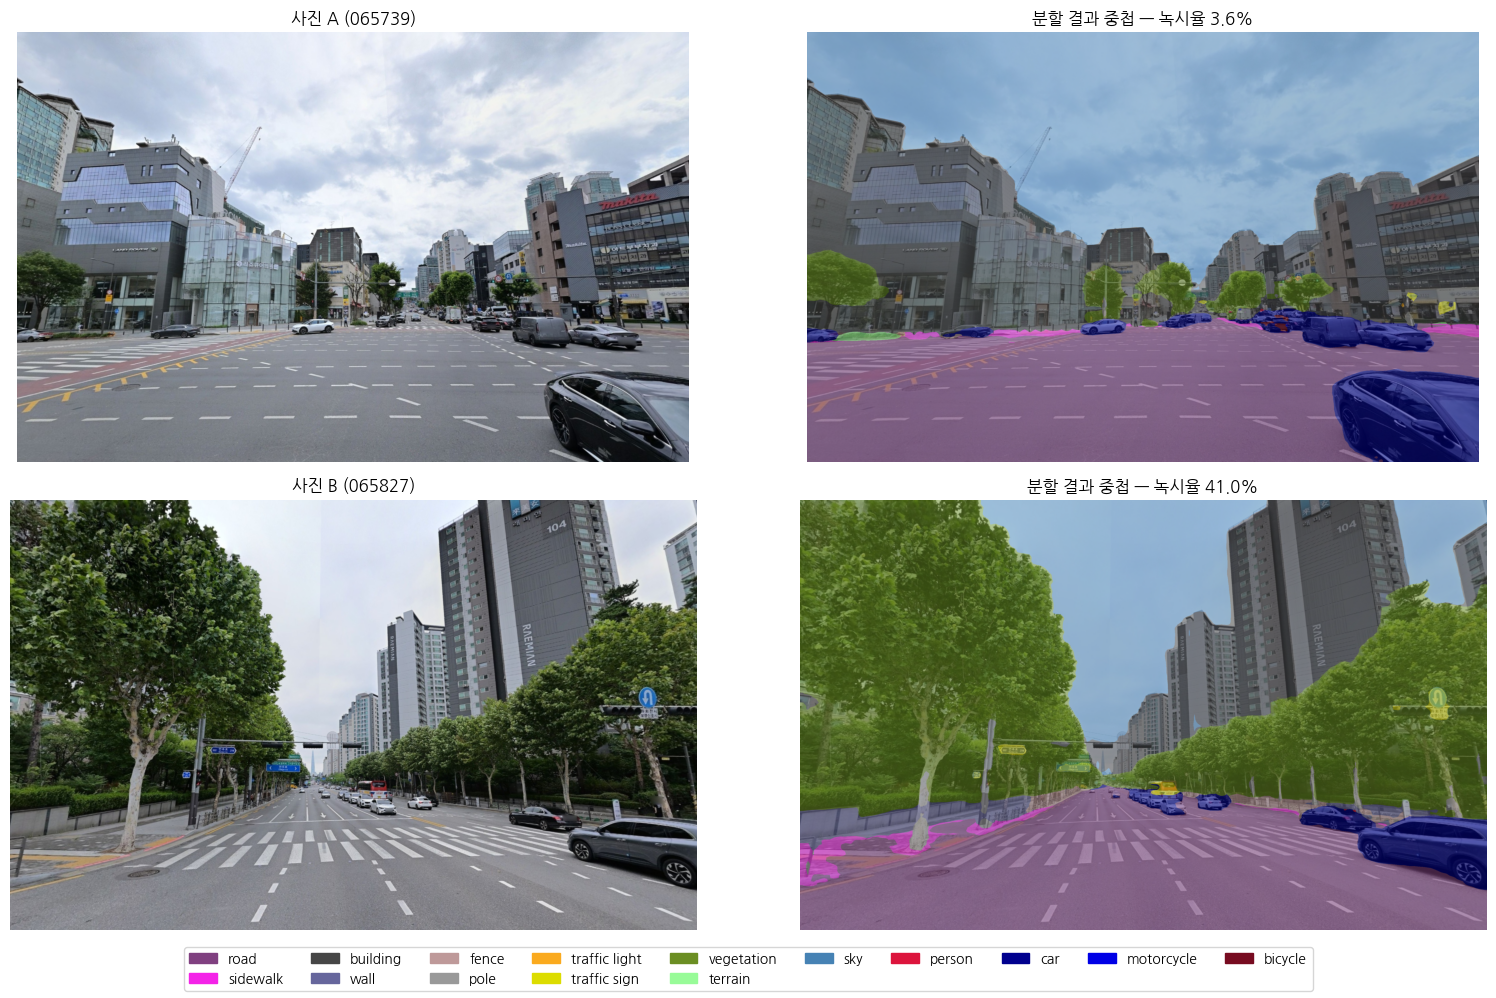

지표                A (065739)    B (065827)     차이(B-A)
vegetation              3.6%         41.0%      +37.4%
sky                    36.6%         14.1%      -22.5%
building               27.6%         14.1%      -13.4%
road                   25.0%         22.9%       -2.1%
sidewalk                0.5%          0.9%       +0.5%
car                     6.3%          3.1%       -3.3%
pole                    0.1%          0.8%       +0.7%
traffic sign            0.1%          0.5%       +0.4%


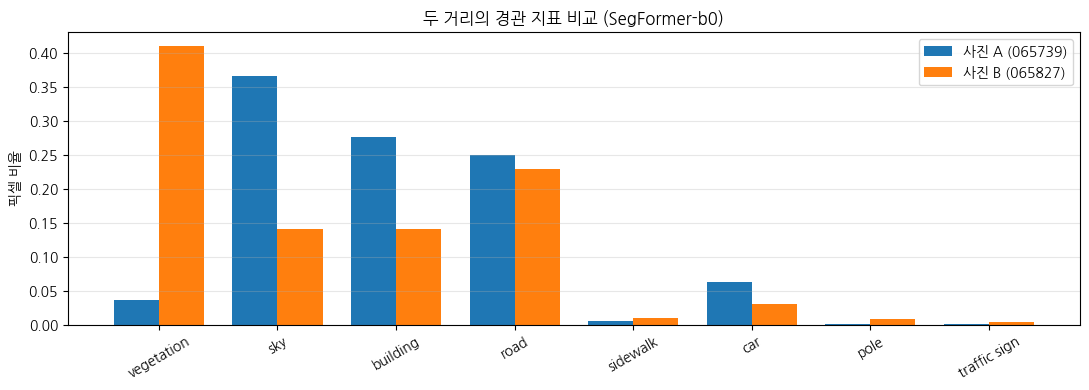

In [23]:
# ===== 사진 한 장을 분할하고 클래스별 비율을 돌려주는 함수 =====
@torch.no_grad()
def segment(img, model=segformer, proc=processor):
    inputs = proc(images=img, return_tensors="pt").to(device)
    logits = model(**inputs).logits                                   # (1, 19, H/4, W/4)
    logits = F.interpolate(logits, size=img.size[::-1], mode="bilinear", align_corners=False)
    seg = logits.argmax(1)[0].cpu().numpy()                           # (H, W) 클래스 번호
    ratio = np.bincount(seg.flatten(), minlength=len(id2label)) / seg.size
    return seg, ratio

# BASE_DIR(lecture10_advanced_models) 기준 상대경로 → rel()로 전체 경로 변환
# = /content/drive/MyDrive/Colab Notebooks/5_스마트도시데이터분석_colab/lecture10_advanced_models/image/...
PHOTOS = {
    "A (065739)": "image/스크린샷 2026-11-08 065739.png",
    "B (065827)": "image/스크린샷 2026-11-08 065827.png",
}
imgs, segs_b0, ratios_b0 = {}, {}, {}
for name, path in PHOTOS.items():
    imgs[name] = Image.open(rel(path)).convert("RGB")
    segs_b0[name], ratios_b0[name] = segment(imgs[name])

# ===== 원본 / 분할 중첩 비교 =====
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for r, name in enumerate(PHOTOS):
    axes[r, 0].imshow(imgs[name]); axes[r, 0].set_title(f"사진 {name}")
    overlay = (0.5 * np.array(imgs[name]) + 0.5 * PALETTE[segs_b0[name]]).astype(np.uint8)
    axes[r, 1].imshow(overlay); axes[r, 1].set_title(f"분할 결과 중첩 — 녹시율 {ratios_b0[name][label2id['vegetation']]:.1%}")
    for ax in axes[r]: ax.axis("off")
used = np.unique(np.concatenate([np.unique(s) for s in segs_b0.values()]))
handles = [mpatches.Patch(color=PALETTE[i] / 255, label=id2label[int(i)]) for i in used]
fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 10))
plt.tight_layout(rect=[0, 0.05, 1, 1]); plt.show()

# ===== 지표 비교 표 + 막대그래프 =====
KEYS = ["vegetation", "sky", "building", "road", "sidewalk", "car", "pole", "traffic sign"]
print(f"{'지표':<14}" + "".join(f"{n:>14}" for n in PHOTOS) + f"{'차이(B-A)':>12}")
for k in KEYS:
    a, b = (ratios_b0[n][label2id[k]] for n in PHOTOS)
    print(f"{k:<14}{a:>14.1%}{b:>14.1%}{b - a:>+12.1%}")

x = np.arange(len(KEYS)); w = 0.38
plt.figure(figsize=(11, 4))
for j, n in enumerate(PHOTOS):
    plt.bar(x + (j - 0.5) * w, [ratios_b0[n][label2id[k]] for k in KEYS], w, label=f"사진 {n}")
plt.xticks(x, KEYS, rotation=30); plt.ylabel("픽셀 비율"); plt.title("두 거리의 경관 지표 비교 (SegFormer-b0)")
plt.legend(); plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# 지표          A(065739)   B(065827)   차이(B-A)
# vegetation       3.6%       41.0%      +37.4%p   ← 녹시율 약 11배
# sky             36.6%       14.1%      -22.5%p
# building        27.6%       14.1%      -13.4%p
# road            25.0%       22.9%       -2.1%p
#
# - 사진 A: 넓은 교차로 + 상업 건물 중심 거리. 가로수가 작고 멀리 있어 녹시율 3.6%,
#   대신 시야가 트여 하늘 비율이 36.6%로 높음 (개방감은 크지만 녹지 체감은 낮은 경관)
# - 사진 B: 양쪽에 큰 가로수(플라타너스류)가 늘어선 대로 + 고층 아파트.
#   나무가 시야의 41%를 덮어 하늘·건물이 가려짐 → 위요감(둘러싸인 느낌)이 강한 녹색 가로
# - 도로 비율은 22~25%로 비슷 → 두 거리의 차이는 "도로 폭"보다 "가로수와 연도 건물"에서 나옴
# - 해석 주의:
#   · 녹시율은 촬영 위치·화각·계절(잎이 무성한 여름 vs 겨울)에 크게 좌우됨 → 같은 조건으로 찍은 사진끼리 비교해야 함
#   · 한 장이 아니라 거리를 따라 여러 지점(예: 50m 간격)의 평균을 내야 거리 단위 지표로 쓸 수 있음
#   · 사진 B의 pole 0.8%는 실제 전신주보다 많음 → 가로수 줄기 일부를 pole로 오분류 (과제 5 참고)

### 추가 과제 4. SegFormer-b0 → b2로 바꾸기
- b0: 약 370만 파라미터의 가장 작은 모델 / b2: 약 2,700만 파라미터로 인코더가 더 깊고 넓음
- 같은 두 사진을 b2로 다시 분할해 (1) 지표 변화, (2) 두 모델이 같은 클래스로 판정한 픽셀 비율(일치도)을 비교

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

파라미터 수 — b0: 3,719,027  /  b2: 27,361,235
사진 A (065739): 픽셀 일치도 97.2%  | 처리 시간 b0 0.10s, b2 0.16s


model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

사진 B (065827): 픽셀 일치도 95.0%  | 처리 시간 b0 0.12s, b2 0.20s

지표               A (065739) b0   A (065739) b2   B (065827) b0   B (065827) b2
vegetation                3.6%            3.2%           41.0%           40.8%
sky                      36.6%           36.5%           14.1%           13.7%
building                 27.6%           27.0%           14.1%           14.2%
road                     25.0%           25.3%           22.9%           23.2%
sidewalk                  0.5%            0.3%            0.9%            0.5%
car                       6.3%            6.5%            3.1%            3.5%
pole                      0.1%            0.2%            0.8%            1.3%
traffic sign              0.1%            0.0%            0.5%            0.6%


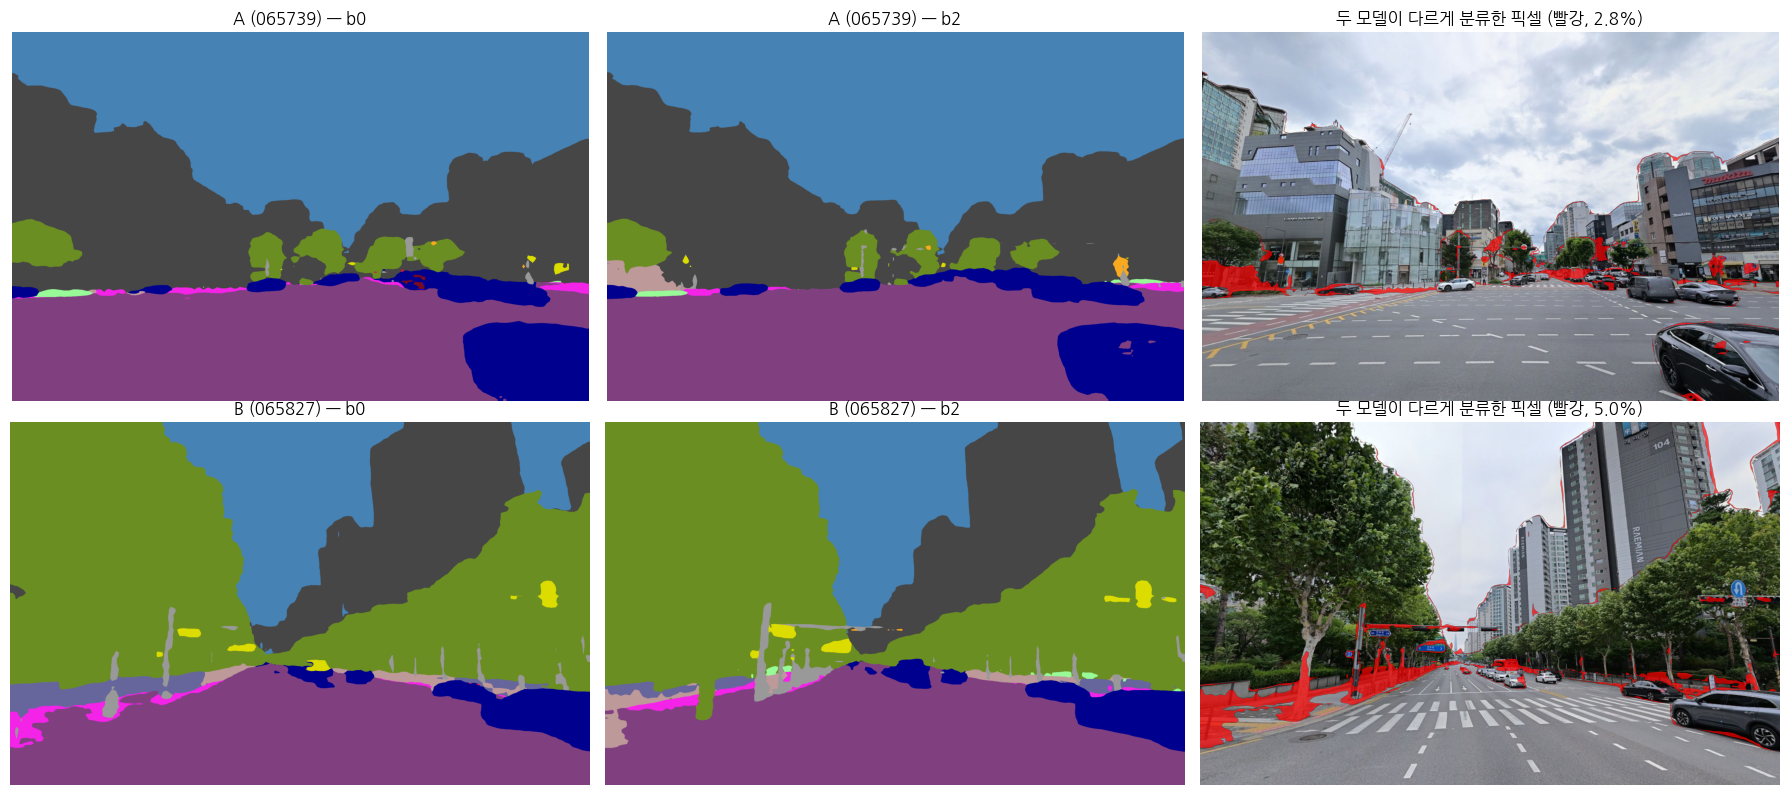

In [24]:
# ===== SegFormer-b2 불러오기 =====
name_b2 = "nvidia/segformer-b2-finetuned-cityscapes-1024-1024"
processor_b2 = SegformerImageProcessor.from_pretrained(name_b2)
segformer_b2 = SegformerForSemanticSegmentation.from_pretrained(name_b2).to(device).eval()
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"파라미터 수 — b0: {n_params(segformer):,}  /  b2: {n_params(segformer_b2):,}")

# ===== 두 사진을 b2로 분할 (처리 시간도 측정) =====
segs_b2, ratios_b2 = {}, {}
for name in PHOTOS:
    t0 = time.time(); segment(imgs[name]); t_b0 = time.time() - t0
    t0 = time.time(); segs_b2[name], ratios_b2[name] = segment(imgs[name], segformer_b2, processor_b2); t_b2 = time.time() - t0
    agree = (segs_b0[name] == segs_b2[name]).mean()                 # 두 모델이 같은 클래스로 본 픽셀 비율
    print(f"사진 {name}: 픽셀 일치도 {agree:.1%}  | 처리 시간 b0 {t_b0:.2f}s, b2 {t_b2:.2f}s")

# ===== 지표 비교 =====
print(f"\n{'지표':<14}" + "".join(f"{n+' b0':>16}{n+' b2':>16}" for n in PHOTOS))
for k in KEYS:
    print(f"{k:<14}" + "".join(f"{ratios_b0[n][label2id[k]]:>16.1%}{ratios_b2[n][label2id[k]]:>16.1%}" for n in PHOTOS))

# ===== 시각 비교: b0 / b2 / 두 모델이 다르게 본 곳 =====
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for r, name in enumerate(PHOTOS):
    axes[r, 0].imshow(PALETTE[segs_b0[name]]); axes[r, 0].set_title(f"{name} — b0")
    axes[r, 1].imshow(PALETTE[segs_b2[name]]); axes[r, 1].set_title(f"{name} — b2")
    diff = segs_b0[name] != segs_b2[name]
    axes[r, 2].imshow(imgs[name]); axes[r, 2].imshow(np.ma.masked_where(~diff, diff), cmap="autumn", alpha=0.7)
    axes[r, 2].set_title(f"두 모델이 다르게 분류한 픽셀 (빨강, {diff.mean():.1%})")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# 파라미터: b0 3,719,027  /  b2 27,361,235 (약 7.4배)
# 픽셀 일치도: 사진 A 97.2%, 사진 B 95.0%   |   처리 시간: b0 0.10~0.12초, b2 0.16~0.20초 (T4 GPU)
#
# 지표          A b0    A b2    B b0    B b2
# vegetation    3.6%    3.2%   41.0%   40.8%
# sky          36.6%   36.5%   14.1%   13.7%
# pole          0.1%    0.2%    0.8%    1.3%
#
# - 핵심 지표(녹시율·하늘·건물·도로)는 두 모델 차이가 0.6%p 이하 → 큰 면적 지표는 작은 b0로도 충분히 안정적
# - 다르게 분류한 픽셀(빨강)은 대부분 "경계"와 "작은 물체"에 몰려 있음
#   · 건물-하늘, 나무-하늘 윤곽선 → 경계 위치가 1~2픽셀 다른 정도
#   · 사진 B 아래쪽 보도·화단: b0는 sidewalk(분홍), b2는 terrain/fence(연갈색)로 다르게 봄
#   · 가로수 줄기·신호등·표지판 같은 가늘고 작은 물체 → b2가 더 많이 잡아 pole 비율이 0.8% → 1.3%로 증가
# - 결론: 모델이 커지면 작은 물체와 경계의 정밀도가 좋아지지만, 녹시율처럼 넓은 면적 비율에는 영향이 거의 없음.
#   대량의 거리 사진(수만 장)을 처리할 때는 b0가 속도 면에서 실용적, 전신주·표지판 개수 같은 세부 분석에는 b2가 유리

### 추가 과제 5. (토론) 유럽 도시(Cityscapes)로 학습한 모델을 한국 거리 사진에 적용할 때 생길 수 있는 오류

**과제 3·4에서 실제로 확인한 오류**
- **가로수 줄기 → pole(기둥)**: 사진 B에서 플라타너스 줄기가 회색(pole)으로 칠해졌어요. b2에서 오히려 더 많이 그래서 pole 비율이 0.8% → 1.3%로 늘었어요. 녹시율은 잎(수관)만 세므로 줄기만큼 녹시율이 조금 낮아지고, 전신주 개수를 세는 분석이라면 과대 집계돼요.
- **화단·보도 경계 혼동**: 사진 B 왼쪽 아래 화단과 보도를 b0는 sidewalk, b2는 terrain/fence로 서로 다르게 봤어요. 한국 보도는 낮은 화단, 볼라드, 보도블록 패턴이 유럽과 달라서 경계가 불안정해요.
- 이 두 곳이 두 모델이 다르게 분류한 픽셀(빨강)이 몰린 영역이에요. 모델이 확신하지 못하는 부분일수록 지역 차이에 민감하다는 신호예요.

**한국 거리에서 예상되는 추가 오류**

| 대상 | 한국 거리의 특징 | 예상 오류 |
|---|---|---|
| **간판** | 건물 전면을 덮는 대형 돌출·세로 간판, 한글, 원색 | Cityscapes에 "간판" 클래스가 없음 → building 또는 traffic sign으로 분류. traffic sign 비율이 과대 산출될 수 있음 |
| **전신주·전선** | 전신주가 많고 전선이 하늘을 가로지름 | 전선은 학습 클래스에 없어 sky나 building으로 흡수. 전신주와 가로수 줄기, 가로등을 모두 pole로 뭉침 |
| **좁은 이면도로** | 차도·보도 구분 없는 골목, 노상 주차, 오토바이 | 차도/보도 구분 기준이 없어 sidewalk와 road가 섞임. 골목 전체를 road로 보거나, 주차 차량이 길을 대부분 가려 road 비율이 과소 산출 |
| **아파트 단지** | 초고층 판상형 아파트가 연속 | 유럽의 5~6층 건물보다 훨씬 커서 하늘과의 경계는 잘 잡지만, 멀리 있는 단지가 sky나 wall로 섞일 수 있음 |
| **교통 시설** | 가로형(옆으로 긴) 신호등, 노란 중앙선, 버스전용차로(빨강/파랑) | 세로형 신호등 위주로 학습해 가로형 신호등 인식률 저하. 색칠된 차로를 다른 클래스로 오인 가능 |
| **기타** | 배달 오토바이, 포장마차, 현수막, 공사 가림막 | motorcycle/rider 혼동, 현수막을 traffic sign이나 fence로 분류 |

**원인과 대응**
- **원인 1: 도메인 차이(domain shift)**: 학습 데이터(독일·스위스 등 50개 도시)와 적용 데이터(한국)의 건축 양식, 시설물, 촬영 조건이 달라요.
- **원인 2: 클래스 정의 차이**: 간판, 전선, 볼라드처럼 한국 거리에서 중요한 요소가 19개 클래스에 아예 없어요.
- **대응**:
  1. 한국 데이터로 미세조정(fine-tuning)해요. 예: AI Hub 보행·자율주행 영상 데이터. 클래스도 필요에 맞게 추가해요.
  2. 모델 출력을 그대로 쓰지 않고, 표본 사진 수십 장을 직접 라벨링해 클래스별 IoU를 검증한 뒤 오류가 큰 클래스는 해석에서 제외하거나 보정해요.
  3. 녹시율처럼 큰 면적 지표는 비교적 안정적이에요 (과제 4에서 b0·b2 차이 0.6%p 이하). 반면 pole, traffic sign 같은 작은 물체 지표는 신뢰도가 낮다는 점을 보고서에 명시해요.